In [1]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 20.2 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Credit Card Fraud Detection DL Model

In [3]:
# Data claning
import pandas as pd
import numpy as np

# Visulizaion
import matplotlib.pyplot as plt
import seaborn as sns

#Model Building
import sklearn

## Data Cleaning

In [4]:
data = pd.read_csv('/content/drive/MyDrive/creditcard.csv')
df = data.copy()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [ ]:
df.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
df.isna().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

## Splitting Data

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
x = df.drop(columns=['Class'])
y= df['Class']

In [7]:
x_train, x_test, y_train, y_test = train_test_split(x,y ,test_size = 0.2, random_state = 42)

x_train.shape, x_test.shape, y_train.shape, y_test.shape

((227845, 30), (56962, 30), (227845,), (56962,))

# Data Preprocessing

### Feature Scaling

In [8]:
from sklearn.preprocessing import StandardScaler

std = StandardScaler()
x_train_scaled = std.fit_transform(x_train)
x_test_scaled = std.transform(x_test)

### Splitting Validation Data

In [9]:
# Split training data into training and validation sets
split = int(len(x_train) * 0.8)

x_val = x_train_scaled[split:]
y_val = y_train[split:]

x_train_split = x_train_scaled[:split]
y_train_split = y_train[:split]

### Hndling Imbalance Data

In [ ]:
y_train.value_counts() # the label is highly imbalance

,count
Class,
0,227451
1,394


In [ ]:
y_test.value_counts()

,count
Class,
0,56864
1,98


In [10]:
# Balanced Training Data Using Smote

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42, sampling_strategy='minority')
x_train_smote, y_train_smote = smote.fit_resample(x_train_split, y_train_split)

y_train_smote.value_counts()

,count
Class,
0,181967
1,181967


# Building Model

In [11]:
import optuna
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [12]:
def objective(trial):

    unit = trial.suggest_int('unit', 38, 512, step = 32)
    activation = trial.suggest_categorical('activation', ['leaky_relu', 'swish', 'gelu', 'elu'])
    optimizer = trial.suggest_categorical('optimizer', ['adam', 'adamw', 'nadam', 'rmsprop'])
    # epochs = trial.suggest_int('epochs', 10, 40, step = 10)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128, 256])
    n_layers = trial.suggest_int('n_layers', 1, 3)

    # Create the ANN model

    # model = Sequential([
    #     layers.Input(shape=(x_train_smote.shape[1],)),
    #     layers.Dense(units=unit, activation=activation),
    #     layers.Dense(units=unit//2, activation=activation),
    #     layers.Dense(1, activation='sigmoid')
    # ])

    model = Sequential()
    model.add(layers.Input(shape=(x_train_smote.shape[1],)))

    for i in range(n_layers):
        units = unit // (2 ** i)
        model.add(layers.Dense(units=units, activation=activation))

    model.add(layers.Dense(1, activation='sigmoid'))


    # Compile the model

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

    history = model.fit(
    x_train_smote,
    y_train_smote,
    validation_data=(x_val, y_val),
    epochs=50,
    batch_size=batch_size,
    callbacks=[early_stop]
    )

    # Validation prediction
    y_prob = model.predict(x_val, verbose=0)

    y_val_pred = (y_prob >= 0.5).astype(int).ravel()

    # Validation metrics
    accuracy = accuracy_score(y_val, y_val_pred)
    precision = precision_score(y_val, y_val_pred)
    recall = recall_score(y_val, y_val_pred)
    f1 = f1_score(y_val, y_val_pred)

    # Save metrics for this trial
    trial.set_user_attr("accuracy", accuracy)
    trial.set_user_attr("precision", precision)
    trial.set_user_attr("recall", recall)

    # Optuna will maximize this
    return f1

In [13]:
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(), study_name='F1_Maximize')

[I 2026-09-03 07:10:54,795] A new study created in memory with name: F1_Maximize


In [14]:
study.optimize(objective, n_trials =25)

/tmp/ipykernel_604/2581009752.py:3: UserWarning: The distribution is specified by [38, 512] and step=32, but the range is not divisible by `step`. It will be replaced with [38, 486].
  unit = trial.suggest_int('unit', 38, 512, step = 32)


Epoch 1/50
1422/1422 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9905 - loss: 0.0272 - val_accuracy: 0.9978 - val_loss: 0.0104
Epoch 2/50
1422/1422 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9985 - loss: 0.0056 - val_accuracy: 0.9984 - val_loss: 0.0098
Epoch 3/50
1422/1422 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9991 - loss: 0.0034 - val_accuracy: 0.9986 - val_loss: 0.0112
Epoch 4/50
1422/1422 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9993 - loss: 0.0030 - val_accuracy: 0.9991 - val_loss: 0.0103
Epoch 5/50
1422/1422 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9995 - loss: 0.0022 - val_accuracy: 0.9990 - val_loss: 0.0112


[I 2026-09-03 07:11:43,647] Trial 0 finished with value: 0.6666666666666666 and parameters: {'unit': 390, 'activation': 'elu', 'optimizer': 'adamw', 'batch_size': 256, 'n_layers': 3}. Best is trial 0 with value: 0.6666666666666666.


Epoch 1/50


/tmp/ipykernel_604/2581009752.py:3: UserWarning: The distribution is specified by [38, 512] and step=32, but the range is not divisible by `step`. It will be replaced with [38, 486].
  unit = trial.suggest_int('unit', 38, 512, step = 32)


...

[I 2026-09-03 08:05:43,212] Trial 23 finished with value: 0.6889952153110048 and parameters: {'unit': 294, 'activation': 'leaky_relu', 'optimizer': 'nadam', 'batch_size': 32, 'n_layers': 1}. Best is trial 11 with value: 0.7540983606557377.


Epoch 1/50


/tmp/ipykernel_604/2581009752.py:3: UserWarning: The distribution is specified by [38, 512] and step=32, but the range is not divisible by `step`. It will be replaced with [38, 486].
  unit = trial.suggest_int('unit', 38, 512, step = 32)


11373/11373 ━━━━━━━━━━━━━━━━━━━━ 52s 4ms/step - accuracy: 0.9916 - loss: 0.0263 - val_accuracy: 0.9885 - val_loss: 0.0470
Epoch 2/50
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - accuracy: 0.9987 - loss: 0.0061 - val_accuracy: 0.9976 - val_loss: 0.0119
Epoch 3/50
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 33s 3ms/step - accuracy: 0.9991 - loss: 0.0045 - val_accuracy: 0.9980 - val_loss: 0.0103
Epoch 4/50
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - accuracy: 0.9992 - loss: 0.0037 - val_accuracy: 0.9989 - val_loss: 0.0102
Epoch 5/50
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - accuracy: 0.9993 - loss: 0.0034 - val_accuracy: 0.9988 - val_loss: 0.0092
Epoch 6/50
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - accuracy: 0.9994 - loss: 0.0030 - val_accuracy: 0.9988 - val_loss: 0.0089
Epoch 7/50
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 33s 3ms/step - accuracy: 0.9994 - loss: 0.0029 - val_accuracy: 0.9988 - val_loss: 0.0097
Epoch 8/50
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 33s 3ms/step - accuracy: 0.9994 - lo

[I 2026-09-03 08:11:04,220] Trial 24 finished with value: 0.7309644670050761 and parameters: {'unit': 38, 'activation': 'leaky_relu', 'optimizer': 'nadam', 'batch_size': 32, 'n_layers': 2}. Best is trial 11 with value: 0.7540983606557377.


## Checking Best Param and Trial

In [ ]:
study.best_trial.user_attrs

{'accuracy': 0.9990783207882552,
 'precision': 0.7171717171717171,
 'recall': 0.8352941176470589}

In [15]:
study.best_trial.user_attrs, study.best_value, study.best_trial.number

({'accuracy': 0.9990124865588448,
  'precision': 0.7040816326530612,
  'recall': 0.8117647058823529},
 0.7540983606557377,
 11)

In [16]:
study.best_params

{'unit': 102,
 'activation': 'leaky_relu',
 'optimizer': 'nadam',
 'batch_size': 32,
 'n_layers': 2}

In [ ]:
study.best_value

0.7717391304347826

In [ ]:
study.best_trial.number

7

In [ ]:
study.best_params

{'unit': 422,
 'activation': 'swish',
 'optimizer': 'adamw',
 'batch_size': 32,
 'n_layers': 3}

### Now Train Model ON Best Params

In [17]:
# Now Train ANN Model ON Best Param
model1 =  Sequential([
        layers.Input(shape=(x_train_smote.shape[1],)),
        layers.Dense(units=study.best_params['unit'], activation=study.best_params['activation']),
        layers.Dense(units=51, activation=study.best_params['activation']),
        layers.Dense(1, activation='sigmoid')
    ])

model1.compile(
        optimizer=study.best_params['optimizer'],
        loss="binary_crossentropy",
        metrics=['accuracy']
    )

history1 = model1.fit(
    x_train_smote,
    y_train_smote,
    epochs=11,
    batch_size=study.best_params['batch_size']
    )

Epoch 1/11
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 44s 4ms/step - accuracy: 0.9940 - loss: 0.0192
Epoch 2/11
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 44s 4ms/step - accuracy: 0.9988 - loss: 0.0054
Epoch 3/11
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - accuracy: 0.9992 - loss: 0.0040
Epoch 4/11
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - accuracy: 0.9993 - loss: 0.0034
Epoch 5/11
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - accuracy: 0.9994 - loss: 0.0029
Epoch 6/11
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - accuracy: 0.9994 - loss: 0.0028
Epoch 7/11
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 30s 3ms/step - accuracy: 0.9996 - loss: 0.0022
Epoch 8/11
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.9996 - loss: 0.0022
Epoch 9/11
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - accuracy: 0.9996 - loss: 0.0020
Epoch 10/11
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - accuracy: 0.9996 - loss: 0.0019
Epoch 11/11
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - accuracy: 0.9997 - loss: 0.00

## Model Evaluation

In [18]:
model1.evaluate(x_test_scaled, y_test)

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9990 - loss: 0.0102


[0.010228231549263, 0.9990344643592834]

In [19]:
y_test_pred = model1.predict(x_test_scaled)
y_train_pred = model1.predict(x_train_smote)

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
11373/11373 ━━━━━━━━━━━━━━━━━━━━ 21s 2ms/step


In [25]:
test_pred_y = [1 if pred>=0.5 else 0 for pred in y_test_pred]
train_pred_y = [1 if pred>=0.5 else 0 for pred in y_train_pred]

In [26]:
from sklearn.metrics import classification_report

In [27]:
print(classification_report(y_train_smote, train_pred_y)) # smoted Training Data Acciracy and Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    181967
           1       1.00      1.00      1.00    181967

    accuracy                           1.00    363934
   macro avg       1.00      1.00      1.00    363934
weighted avg       1.00      1.00      1.00    363934



In [28]:
print(classification_report(y_test, test_pred_y)) # Testing Data Accuracy and Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.67      0.85      0.75        98

    accuracy                           1.00     56962
   macro avg       0.84      0.92      0.88     56962
weighted avg       1.00      1.00      1.00     56962



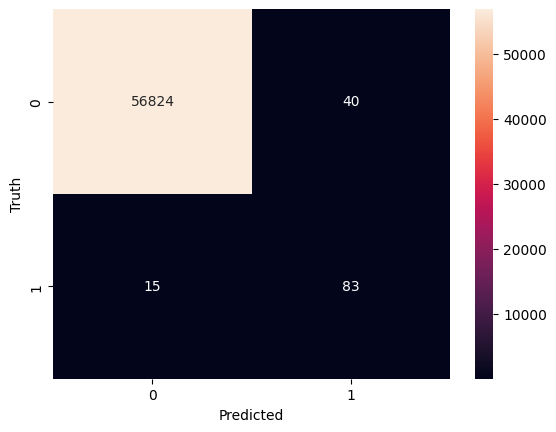

In [49]:
# Confusion Matrix

cm = tf.math.confusion_matrix(labels=y_test, predictions=test_pred_y)
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()

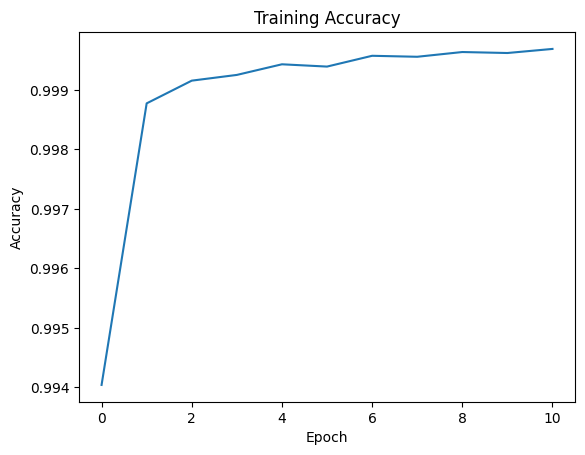

In [51]:
# Training Accuracy
plt.plot(history1.history['accuracy'])
plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()

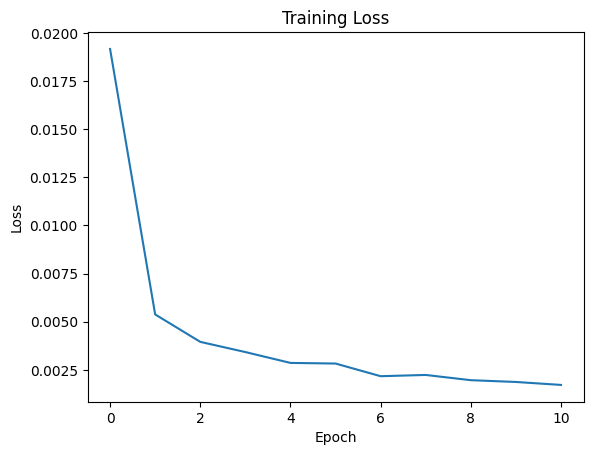

In [52]:
# Training Loss
plt.plot(history1.history['loss'])
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

## Saving Model

In [30]:
model1.save('/content/drive/MyDrive/fraud_ann_final_model.keras')

In [31]:
import os

os.path.exists('/content/drive/MyDrive/fraud_ann_final_model.keras')

True

## Final Model Evaluation & Conclusion

### Classification Metrics Breakdown:
- **Fraud Detection (Recall):** **85%** — Model successfully identified 83 out of 98 fraud cases.
- **Precision:** **67%** — Out of all predicted fraud alerts, 67% were true positive frauds.
- **F1-Score:** **0.75** — Strong trade-off achieved between Precision and Recall for Class 1.
- **Overall Accuracy:** **99.9%** (1.00) — High baseline classification across all 56,962 validation samples.

### Key Takeaways:
1. **Effective Fraud Catch Rate:** Achieving an **85% Recall** on highly imbalanced credit card fraud data demonstrates that the tuned Deep Learning / ANN architecture effectively captures minority class patterns.
2. **Controlled False Positives:** With a **67% Precision**, false alarms remain at a manageable level for transaction monitoring workflows.
3. **Hyperparameter Optimization:** Optuna tuning allowed the network to learn robust feature representations without overfitting to the majority class.